# Context
It is important that credit card companies are able to recognize fraudulent credit card transactions so that customers are not charged for items that they did not purchase.

# Content
The dataset contains transactions made by credit cards in September 2013 by European cardholders.
This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. Feature 'Time' contains the seconds elapsed between each transaction and the first transaction in the dataset. The feature 'Amount' is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. Feature 'Class' is the response variable and it takes value 1 in case of fraud and 0 otherwise.

Given the class imbalance ratio, we recommend measuring the accuracy using the Area Under the Precision-Recall Curve (AUPRC). Confusion matrix accuracy is not meaningful for unbalanced classification.

# 01. Exploratory Data Analysis: Credit Card Fraud Detection

understanding the data before modeling, and decide how to handle imbalance and data quality.

**Dataset:** Kaggle Credit Card Fraud Detection (ULB). European card transactions over two days. Features V1-V28 are PCA-transformed (anonymized), plus `Time`, `Amount`, and the target `Class` (1 = fraud).

# Loading Data

In [1]:
import sys
sys.path.append('..')

from src.data import load_data
path = "../data/raw/creditcard.csv"
df = load_data(path)
df.head(5)

Loading data from ../data/raw/creditcard.csv...


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.tail(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [3]:
print(f'Total Null Values in Dataset: {df.isnull().sum().sum()}')

Total Null Values in Dataset: 0


Great so dataset has no null values

In [ ]:
print(f'Actual transactions: {df["Class"].value_counts()[0]}')
print(f'Fraud transactions: {df["Class"].value_counts()[1]}')

Legit transactions: 284315
Fraud transactions: 492


C:\Users\HP\AppData\Local\Temp\ipykernel_26896\387361306.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df , palette=colors)


[]

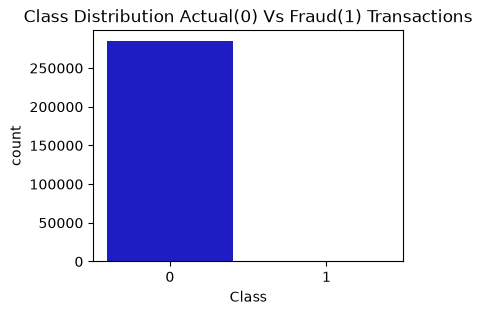

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
colors = ["#0101DF", "#DF0101"]
plt.figure(figsize=(4,3))
sns.countplot(x='Class', data=df , palette=colors)
plt.title("Class Distribution Actual(0) Vs Fraud(1) Transactions")
plt.plot()

Note: Notice how imbalanced is our original dataset! Most of the transactions are non-fraud. If we use this dataframe as the base for our predictive models and analysis we might get a lot of errors and our algorithms will probably overfit since it will "assume" that most transactions are not fraud. But we don't want our model to assume, we want our model to detect patterns that give signs of fraud!

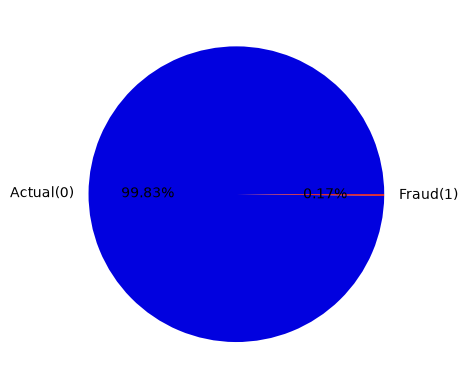

In [34]:
class_counts = df['Class'].value_counts()

plt.Figure(figsize=(2,3))
plt.pie(x = class_counts, labels=['Actual(0)', 'Fraud(1)'],colors= colors, autopct="%.2f%%")
plt.show()

In [6]:
print(f'Total transactions: {df.shape[0]}')
print(f'Duplicates transactions: {df[df.duplicated].shape[0]}')

Total transactions: 284807
Duplicates transactions: 1081


In [7]:
print(f'Legit Duplicate Transcations: {df[df.duplicated]["Class"].value_counts()[0]}')
print(f'Fraud Duplicate Transcations: {df[df.duplicated]["Class"].value_counts()[1]}')

Legit Duplicate Transcations: 1062
Fraud Duplicate Transcations: 19


so 492 fraud transactions and 19 were duplicates